In [1]:
import sys
import os

sys.path.append(os.path.abspath(".."))

In [2]:
import kagglehub
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from core.linear_regression import LinearRegression
from utils import training, loss

np.random.seed(42)

### Dataset ophalen en inladen

In [3]:
path = kagglehub.dataset_download("iamsouravbanerjee/house-rent-prediction-dataset")
file_path = os.path.join(path, 'House_Rent_Dataset.csv')

houserent = pd.read_csv(file_path)
houserent.head()

,Posted On,BHK,Rent,Size,Floor,Area Type,Area Locality,City,Furnishing Status,Tenant Preferred,Bathroom,Point of Contact
0,2022-05-18,2,10000,1100,Ground out of 2,Super Area,Bandel,Kolkata,Unfurnished,Bachelors/Family,2,Contact Owner
1,2022-05-13,2,20000,800,1 out of 3,Super Area,"Phool Bagan, Kankurgachi",Kolkata,Semi-Furnished,Bachelors/Family,1,Contact Owner
2,2022-05-16,2,17000,1000,1 out of 3,Super Area,Salt Lake City Sector 2,Kolkata,Semi-Furnished,Bachelors/Family,1,Contact Owner
3,2022-07-04,2,10000,800,1 out of 2,Super Area,Dumdum Park,Kolkata,Unfurnished,Bachelors/Family,1,Contact Owner
4,2022-05-09,2,7500,850,1 out of 2,Carpet Area,South Dum Dum,Kolkata,Unfurnished,Bachelors,1,Contact Owner


### Dataset

#### Floor

De strings uit kolom floor omzetten naar numerieke waarden via 2 kolommen: de verdieping van de woning en het totaal aantal verdiepingen van het complex

In [4]:
# Verdieping met maar een enkel woord opvatten als missende waarde voor het totaal
# aantal verdiepingen.
mask = houserent["Floor"].str.split(" ").str.len() == 1
houserent.loc[mask, "Floor"] = houserent.loc[mask, "Floor"].apply(
    lambda x: f"{x} out of NaN"
)

# Totaal aantal verdiepingen uit de string halen en eventuele missende waarden vervangen
# door het gemiddelde van het totaal aantal verdiepingen.
houserent["TotalFloors"] = pd.to_numeric(houserent["Floor"].apply(
    lambda x: x.split(" out of ")[-1]
).replace("NaN", np.nan))
houserent["TotalFloors"] = houserent["TotalFloors"].fillna(houserent["TotalFloors"].mean())

# Verdieping uit de string halen, waarbij verdiepingen uitgedrukt in woorden vervangen
# worden door numerieke waarden.
houserent["Floor"] = houserent["Floor"].apply(
    lambda x: x.split(" out of ")[0]
)
floor_mapping = {
    "Ground" : 0,
    "Upper Basement": -1, 
    "Lower Basement": -2
}
houserent["Floor"] = houserent["Floor"].replace(floor_mapping)
houserent["Floor"] = pd.to_numeric(houserent["Floor"])

#### Categorische kolommen omzetten naar numerieke

Hierbij wordt onderscheid gemaakt tussen categorieën waarin een logische volgorde te herkennen is (ordinaal) en categorieën zonder duidelijke volgorde (nominaal).

In [5]:
# Ordinale categorieën
mapping = {
    "Unfurnished": 0,
    "Semi-Furnished": 1,
    "Furnished": 2
}
houserent["Furnishing Status"] = (houserent["Furnishing Status"]
                                    .map(mapping).astype(int))


# Nominale categorieën
houserent = pd.get_dummies(houserent, columns=["Area Type", 
                                               "City", 
                                               "Point of Contact", 
                                               "Tenant Preferred"])

#### Datum omzetten

Datums omzetten naar het aantal dagen vanaf de eerste datum in de dataset.

In [6]:
houserent["Posted On"] = pd.to_datetime(houserent["Posted On"])

# Aantal dagen vanaf min_date
min_date = houserent["Posted On"].min()
houserent["Posted On"] = houserent["Posted On"].apply(
    lambda x: x - min_date
).dt.days

#### Omzetten naar numpy arrays

Dataset wordt gesplitst in een train-, validation- en testset met respectievelijk 70%, 15% en 15% van de data.

Target wordt gedeeld door 1000, om het model stabieler te laten voorspellen. Numerieke features in de input data worden genormaliseerd.

In [7]:
# Area Locality verwijderen, omdat kolom te veel verschillende waarden heeft.
houserent = houserent.drop(columns=["Area Locality"])

# Datapunt(en) met extreme waarden verwijderen, om variatie in datasets stabiel te houden.
houserent = houserent[houserent["Rent"] != 3_500_000]

# Dataset splitsen in input en output data.
output_feature = 'Rent'
input_features = houserent.columns.to_list()
input_features.remove(output_feature)

X = houserent[input_features]
y = np.array(houserent[output_feature], dtype=np.float64).reshape(-1, 1) / 1_000

# Dataset verdelen in een train-, validation- en testset.
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.3, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42)

# Numerieke waarden in de input data normaliseren.
scaled_features = houserent.select_dtypes(exclude="bool").columns.to_list()
scaled_features.remove(output_feature)

scaler = StandardScaler()

X_train[scaled_features] = scaler.fit_transform(X_train[scaled_features])
X_val[scaled_features] = scaler.transform(X_val[scaled_features])
X_test[scaled_features] = scaler.transform(X_test[scaled_features])

# Input data omzetten naar numpy arrays.
X_train = np.array(X_train, dtype=np.float64)
X_val = np.array(X_val, dtype=np.float64)
X_test = np.array(X_test, dtype=np.float64)

print("Train set: ", X_train.shape, y_train.shape)
print("Validation set: ", X_val.shape, y_val.shape)
print("Test set: ", X_test.shape, y_test.shape)

Train set:  (3321, 22) (3321, 1)
Validation set:  (712, 22) (712, 1)
Test set:  (712, 22) (712, 1)


### Trainen

Hyperparameters (epochs en learning rate) en model worden geïnitialiseerd, waarna het model wordt getraind en de gewichten worden opgeslagen.

Epoch    0 | train cost: 4752.0892 | validation cost: 4649.3036
Epoch   10 | train cost: 3530.9395 | validation cost: 3601.9991
Epoch   20 | train cost: 2850.8293 | validation cost: 3032.3668
Epoch   30 | train cost: 2469.2331 | validation cost: 2722.4751
Epoch   40 | train cost: 2252.8127 | validation cost: 2553.4624
Epoch   50 | train cost: 2128.0979 | validation cost: 2460.5552
Epoch   60 | train cost: 2054.5138 | validation cost: 2408.5221
Epoch   70 | train cost: 2009.5979 | validation cost: 2378.2631
Epoch   80 | train cost: 1980.8818 | validation cost: 2359.4779
Epoch   90 | train cost: 1961.4229 | validation cost: 2346.6557
Epoch   99 | train cost: 1948.5782 | validation cost: 2337.7733


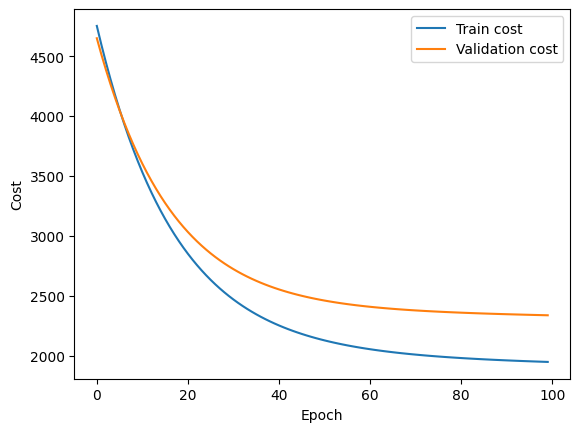

In [8]:
epochs = 100
lr = 0.01
num_features = X_train.shape[1]

model = LinearRegression(f_in=num_features)

model_path = './trained_models/house_rent.npz'

train_costs, val_costs = training.model_fit(model, X_train, y_train, 
                                            cost_function=loss.MSE, epochs=epochs, lr=lr,
                                            X_val=X_val, y_val=y_val)

model.save(model_path)

plt.plot(train_costs, label="Train cost")
plt.plot(val_costs, label="Validation cost")
plt.xlabel('Epoch')
plt.ylabel('Cost')
plt.legend()
plt.show()

### Testen

In [9]:
model_path = './trained_models/house_rent.npz' 

model = LinearRegression(num_features)
model.load(model_path)
pred = model.forward(X_test)

mse = loss.MSE(pred, y_test)
rmse = np.sqrt(mse)
mae = loss.MAE(pred, y_test)

print(f"MSE: {mse:.2f}")
print(f"RMSE: {rmse:.2f}")
print(f"MAE: {mae:.2f}")

MSE: 1446.78
RMSE: 38.04
MAE: 21.82
